У цьому домашньому завданні ми будемо працювати з набором даних Tips. Нижче інформація про нього.

**Про датасет:**

Tips - це датасет, який містить інформацію про рахунки та чайові в ресторані.

**Колонки датасету:**
- `total_bill` - загальна сума рахунку (долари)
- `tip` - розмір чайових (долари)
- `sex` - стать відвідувача (Male/Female)
- `smoker` - чи курить (Yes/No)
- `day` - день тижня (Thur/Fri/Sat/Sun)
- `time` - час відвідування (Lunch/Dinner)
- `size` - розмір групи (кількість людей)

**Джерело:** Оригінальні дані зібрані в одному з американських ресторанів у 1990-х роках. Скачати і переглянути набір даних можна тут: https://www.kaggle.com/datasets/sakshisatre/tips-dataset

А також ми вже вивантажили файл з даними і завантажили вам у Матеріали до цього модуля.




**1. Гістограма розподілу рахунків**
Завантажте датасет Tips (Чайові) з файла у матеріалах `tips.csv`.
Створіть гістограму для колонки `total_bill` з 20 bins.
Опціонально можна додати підписи осей ОХ, ОУ, а також назву графіку.

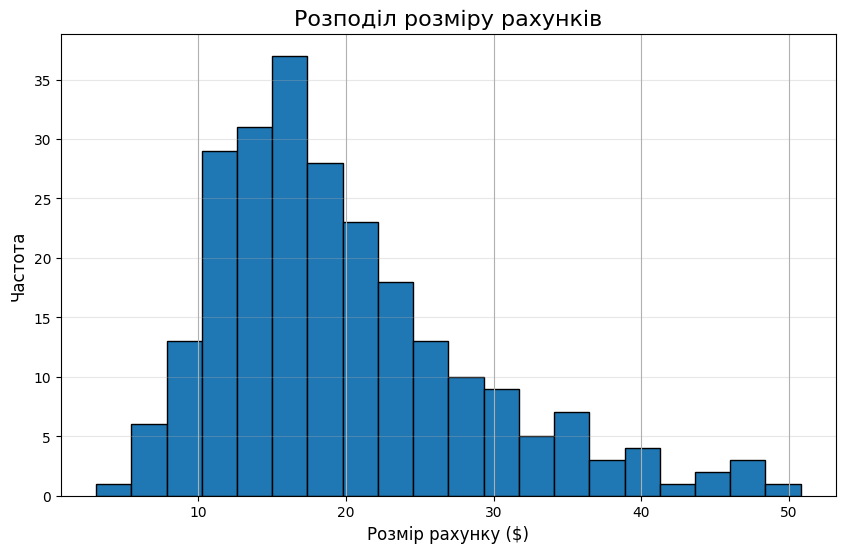

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Завантаження
df = pd.read_csv('tips.csv')

# Гістограма
df['total_bill'].hist(bins=20, edgecolor='black', figsize=(10, 6))
plt.title('Розподіл розміру рахунків', fontsize=16)
plt.xlabel('Розмір рахунку ($)', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.show()

---

**2. Box plot чайових за днями тижня**

Створіть box plot, який показує розподіл чайових (`tip`) за днями тижня (`day`).
В який день навище медіанне значення чайоивх? Зелена горизонтальна лінія всередині кожного box-plot.


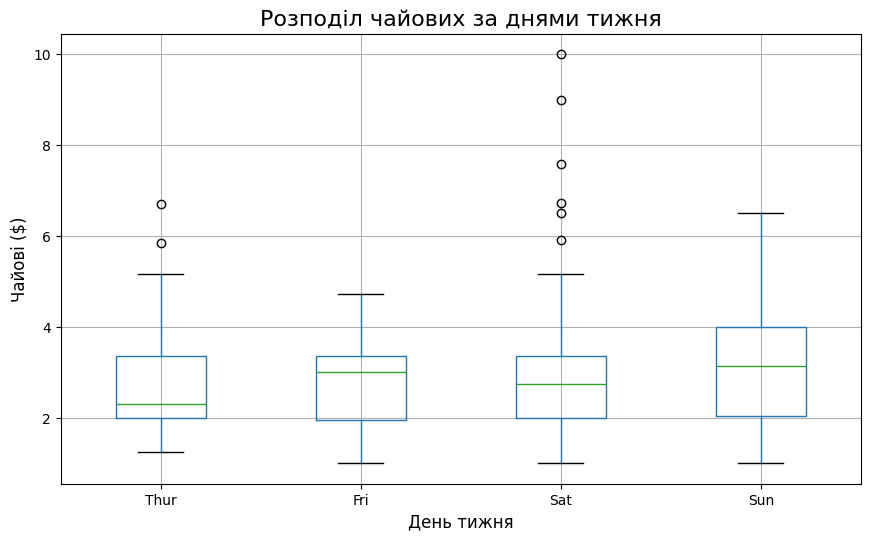

In [ ]:
# Box plot
df.boxplot(column='tip', by='day', figsize=(10, 6))
plt.title('Розподіл чайових за днями тижня', fontsize=16)
plt.suptitle('')  # Прибираємо автоматичний заголовок
plt.xlabel('День тижня', fontsize=12)
plt.ylabel('Чайові ($)', fontsize=12)
plt.show()

---

**3. Scatter plot: рахунок vs чайові**

Створіть діаграму розсіювання для `total_bill` та `tip`.

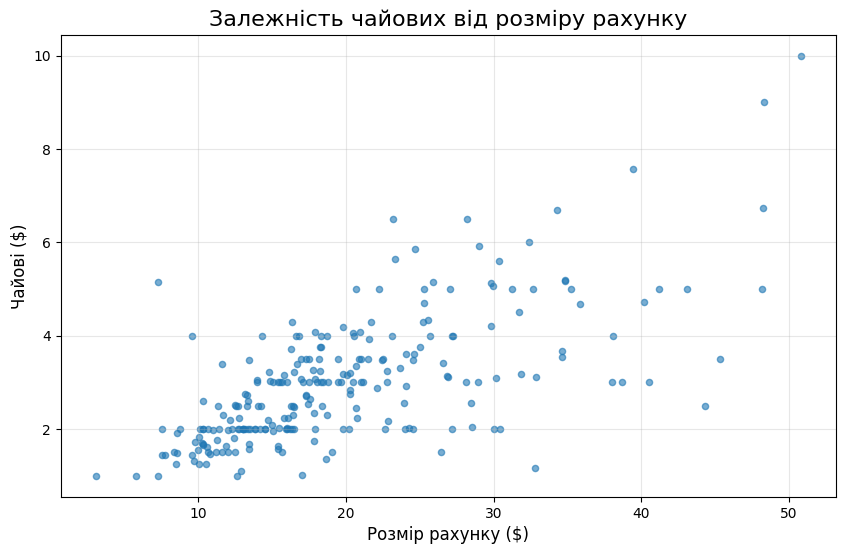

In [ ]:
df.plot.scatter(x='total_bill', y='tip', figsize=(10, 6), alpha=0.6)
plt.title('Залежність чайових від розміру рахунку', fontsize=16)
plt.xlabel('Розмір рахунку ($)', fontsize=12)
plt.ylabel('Чайові ($)', fontsize=12)
plt.grid(alpha=0.3)
plt.show()

---

**4. Bar chart: середній рахунок за часом**

Створіть стовпчасту діаграму середнього рахунку за часом дня (`time`).

/tmp/ipython-input-1816982946.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_bill_by_time = df.groupby('time')['total_bill'].mean()


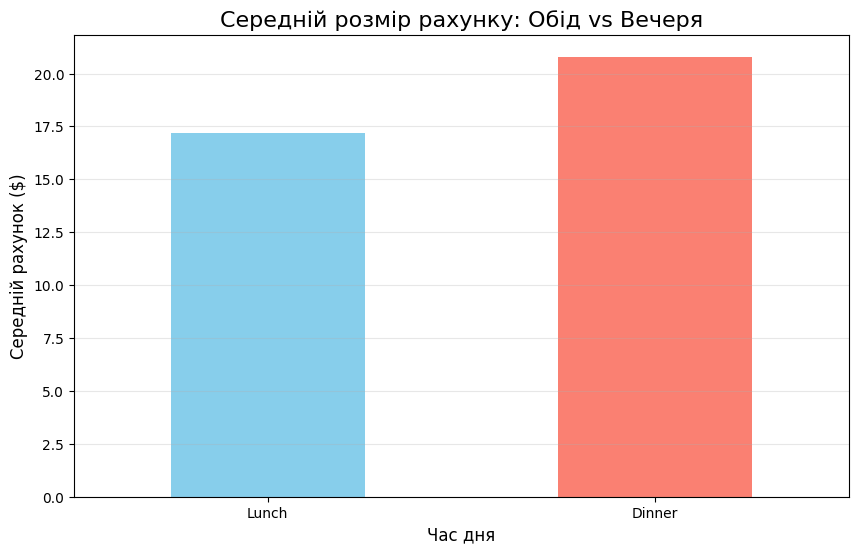

In [ ]:
# Групування та bar chart
avg_bill_by_time = df.groupby('time')['total_bill'].mean()

avg_bill_by_time.plot(kind='bar', figsize=(10, 6), color=['skyblue', 'salmon'])
plt.title('Середній розмір рахунку: Обід vs Вечеря', fontsize=16)
plt.xlabel('Час дня', fontsize=12)
plt.ylabel('Середній рахунок ($)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show();

---

**5. Інтерактивна діаграма розсіювання**

Створіть з допомогою бібліотек Plotly інтерактивний scatter plot для `total_bill` vs `tip` з кольором за статтю (`sex`).


In [ ]:
import plotly.express as px

fig = px.scatter(
    df,
    x='total_bill',
    y='tip',
    color='sex',
    size='size',  # Розмір точки = розмір групи
    hover_data=['day', 'time'],
    title='Залежність чайових від рахунку (інтерактивна)',
    labels={
        'total_bill': 'Розмір рахунку ($)',
        'tip': 'Чайові ($)',
        'sex': 'Стать',
        'size': 'Розмір групи'
    }
)
fig.show()

---

**6. Інтерактивний box plot: чайові за днями та статтю**

Створіть інтерактивний box plot для чайових за днями тижня з розбивкою за кольором по статі.

In [ ]:
fig = px.box(
    df,
    x='day',
    y='tip',
    color='sex',
    title='Розподіл чайових за днями тижня та статтю',
    labels={
        'day': 'День тижня',
        'tip': 'Чайові ($)',
        'sex': 'Стать'
    },
    category_orders={
        'day': ['Thur', 'Fri', 'Sat', 'Sun']
    }
)
fig.show()